# 01 – Data: StatsBomb open data → model-ready tables

**Project:** expected goals (xG) from freeze frames, comparing a **set** neural network with a **graph** neural network.

This notebook downloads everything it needs from the internet and writes the tables used by `02-Analysis.ipynb`.

| Stage | Reads | Writes |
|---|---|---|
| 1. Download and convert | StatsBomb open data JSON on GitHub (`hudl/open-data`) | `data/raw/*.csv` |
| 2. Model-ready tables | `data/raw/shots.csv`, `data/raw/freeze_frames.csv` | `data/processed/shot_table.csv`, `player_table.csv`, `feature_columns.json` |

**Scope:** all men's top-5 league matches in the open data (Premier League, La Liga, Serie A, Bundesliga, Ligue 1).
Most of these are four complete 2015/16 seasons; the rest are seasons where StatsBomb released only one club's matches.
Both kinds are flagged so the analysis can compare them.

**How to run:** `pip install requests pandas numpy matplotlib`, then *Run All*. The first run downloads about
2,200 event files (a few minutes, depending on the connection). Downloads are cached in `data/raw/`, so re-running is quick
and an interrupted run carries on where it stopped.

**Data licence:** StatsBomb open data requires attribution, see https://github.com/hudl/open-data

## 0. Setup

In [1]:
import json
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

BASE = "https://raw.githubusercontent.com/hudl/open-data/master/data"

RAW = Path("data/raw")
PROCESSED = Path("data/processed")
FIGURES = Path("figures")
for folder in (RAW, RAW / "shots", RAW / "matches", PROCESSED, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

MAX_WORKERS = 8           # parallel downloads
DEBUG_MAX_MATCHES = None  # e.g. 50 for a quick dry run; None = everything

TOP5 = {
    "Premier League": ("England", "Premier League"),
    "La Liga": ("Spain", "La Liga"),
    "Serie A": ("Italy", "Serie A"),
    "Bundesliga": ("Germany", "1. Bundesliga"),
    "Ligue 1": ("France", "Ligue 1"),
}
# The 'clean' subset: four complete league seasons from 2015/16 (the 2015/16 Bundesliga is not complete in the open data).
SUBSET_1516 = {("Premier League", "2015/2016"), ("La Liga", "2015/2016"),
               ("Serie A", "2015/2016"), ("Ligue 1", "2015/2016")}

# Pitch geometry (StatsBomb coordinates: 120 x 80 yards, every shot attacks towards x = 120).
PITCH_L, PITCH_W = 120.0, 80.0
GOAL_X, GOAL_Y = 120.0, 40.0
POST_LOW, POST_HIGH = 36.0, 44.0
BODY_RADIUS = 0.5  # yards; used for the "how much of the goal does this player block" feature

CHECKS = []
def check(name, condition, detail=""):
    CHECKS.append((name, bool(condition), detail))
    print(f"{'PASS' if condition else 'FAIL'}  {name}  {detail}")

# Stage 1: download and convert to CSV

## 1.1 Download helpers
Requests retry on temporary server errors, and files are written to a temporary name first, so an interrupted
download cannot leave a broken cache file.

In [2]:
session = requests.Session()
retry = Retry(total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retry, pool_maxsize=MAX_WORKERS * 2))

def write_atomic(path, text):
    tmp = Path(str(path) + ".tmp")
    tmp.write_text(text, encoding="utf-8")
    tmp.replace(path)

def get_json(url):
    # Download JSON; return None if the file does not exist (404).
    response = session.get(url, timeout=60)
    if response.status_code == 404:
        return None
    response.raise_for_status()
    return response.json()

def cached_json(url, path):
    # Load JSON from the local cache, or download and cache it.
    path = Path(path)
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    data = get_json(url)
    if data is not None:
        write_atomic(path, json.dumps(data))
    return data

## 1.2 Competitions: men's top-5 league seasons

In [3]:
comp_df = pd.DataFrame(cached_json(f"{BASE}/competitions.json", RAW / "competitions.json"))

is_male = comp_df["competition_gender"] == "male"
not_youth = ~comp_df.get("competition_youth", pd.Series(False, index=comp_df.index)).fillna(False).astype(bool)

parts = []
for league, (country, name) in TOP5.items():
    sel = comp_df[is_male & not_youth & (comp_df["country_name"] == country)
                  & (comp_df["competition_name"] == name)].copy()
    if sel.empty:
        print(f"WARNING: no rows found for {league}")
        continue
    sel["league"] = league
    parts.append(sel)

league_seasons = pd.concat(parts, ignore_index=True)
print(f"{len(league_seasons)} men's top-5 league seasons found")
league_seasons.groupby("league").size()

27 men's top-5 league seasons found


league
Bundesliga         2
La Liga           18
Ligue 1            3
Premier League     2
Serie A            2
dtype: int64

## 1.3 Matches, season completeness and the focus club
* `season_complete` is `True` if the season is a full double round-robin (every team plays every other team home and away).
* In an incomplete season StatsBomb released one club's matches. That club is the **focus club** (the team that
  appears in every match of that season). These seasons are a biased sample: one, usually very strong, team appears in every match.
* `subset_1516` marks the four complete 2015/16 seasons.

In [4]:
match_rows = []
for _, c in league_seasons.iterrows():
    cid, sid = int(c["competition_id"]), int(c["season_id"])
    matches = cached_json(f"{BASE}/matches/{cid}/{sid}.json", RAW / "matches" / f"{cid}_{sid}.json") or []
    matches = [m for m in matches if m.get("match_status") == "available"]

    pairs = [(m["home_team"]["home_team_name"], m["away_team"]["away_team_name"]) for m in matches]
    teams = {t for pair in pairs for t in pair}
    n_teams, pair_counts = len(teams), Counter(pairs)
    complete = (n_teams >= 2 and len(matches) == n_teams * (n_teams - 1)
                and set(pair_counts) == {(h, a) for h in teams for a in teams if h != a})

    # focus club = the team that plays in every match of an incomplete season
    team_games = Counter(t for pair in pairs for t in pair)
    focus = [t for t, n in team_games.items() if n == len(matches)]
    focus_team = focus[0] if (not complete and len(focus) == 1) else None

    for m in matches:
        match_rows.append({
            "match_id": m["match_id"], "league": c["league"], "season": c["season_name"],
            "match_date": m.get("match_date"),
            "home_team": m["home_team"]["home_team_name"], "away_team": m["away_team"]["away_team_name"],
            "season_complete": complete, "focus_team": focus_team,
            "subset_1516": (c["league"], c["season_name"]) in SUBSET_1516,
        })

matches_df = pd.DataFrame(match_rows)
if DEBUG_MAX_MATCHES:
    matches_df = matches_df.sample(DEBUG_MAX_MATCHES, random_state=0).reset_index(drop=True)
    print(f"DEBUG MODE: random sample of {len(matches_df)} matches")
print(f"{len(matches_df)} matches to download")

2169 matches to download


## 1.4 Events → shots with freeze frames
For each match we download the full event file, keep only the `Shot` events and cache just those.
The **freeze frame** is the list of visible players (location, team, position) at the moment of the shot.
The shooter is not in the freeze frame: their position is the shot location.

In [5]:
def get_shots(match_id):
    # Extract the shots from one match (from the local cache if available).
    cache = RAW / "shots" / f"{match_id}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))

    events = get_json(f"{BASE}/events/{match_id}.json") or []
    shots = []
    for e in events:
        if e.get("type", {}).get("name") != "Shot":
            continue
        s = e.get("shot", {})
        location = e.get("location") or [None, None]
        outcome = s.get("outcome", {}).get("name")
        shots.append({
            "shot_id": e["id"], "match_id": match_id,
            "minute": e.get("minute"), "second": e.get("second"), "period": e.get("period"),
            "team": e.get("team", {}).get("name"), "player": e.get("player", {}).get("name"),
            "play_pattern": e.get("play_pattern", {}).get("name"),
            "under_pressure": e.get("under_pressure", False),
            "location_x": location[0], "location_y": location[1],
            "end_location": s.get("end_location"),
            "shot_type": s.get("type", {}).get("name"),
            "body_part": s.get("body_part", {}).get("name"),
            "technique": s.get("technique", {}).get("name"),
            "first_time": s.get("first_time", False),
            "outcome": outcome, "is_goal": outcome == "Goal",
            "statsbomb_xg": s.get("statsbomb_xg"),   # benchmark only, never a model input
            "freeze_frame": s.get("freeze_frame"),
        })
    write_atomic(cache, json.dumps(shots))
    return shots

all_shots = []
match_ids = matches_df["match_id"].tolist()
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
    t0, n = time.time(), len(match_ids)
    checkpoints = {round(n * k / 10) for k in range(1, 11)}          # print progress every 10%
    for i, shots in enumerate(ex.map(get_shots, match_ids), 1):
        all_shots.extend(shots)
        if i in checkpoints:
            print(f"matches done: {i:,}/{n:,} ({i / n:.0%}, {time.time() - t0:.0f}s)")
print(f"{len(all_shots):,} shots extracted")

matches done: 217/2,169 (10%, 1s)
matches done: 434/2,169 (20%, 1s)
matches done: 651/2,169 (30%, 2s)
matches done: 868/2,169 (40%, 2s)
matches done: 1,084/2,169 (50%, 3s)
matches done: 1,301/2,169 (60%, 3s)
matches done: 1,518/2,169 (70%, 4s)
matches done: 1,735/2,169 (80%, 4s)
matches done: 1,952/2,169 (90%, 5s)
matches done: 2,169/2,169 (100%, 5s)
54,153 shots extracted


## 1.5 Build the raw tables
A freeze frame is a list inside each shot, which a CSV cannot hold, so it becomes its own table with one row per
visible player. `shot_id` links `shots.csv` to `freeze_frames.csv`; `match_id` links shots to matches.

In [6]:
shots_df = pd.DataFrame(all_shots)

end = shots_df["end_location"].apply(lambda l: (list(l) + [None] * 3)[:3] if isinstance(l, list) else [None] * 3)
shots_df[["end_x", "end_y", "end_z"]] = pd.DataFrame(end.tolist(), index=shots_df.index)

ff_rows, ff_stats = [], []
for shot_id, ff in zip(shots_df["shot_id"], shots_df["freeze_frame"]):
    if not isinstance(ff, list) or len(ff) == 0:
        ff_stats.append((0, 0, 0, False))
        continue
    n_team, opp_keeper = 0, False
    for p in ff:
        loc = p.get("location") or [None, None]
        position = p.get("position", {}).get("name")
        teammate = bool(p.get("teammate", False))
        is_keeper = position == "Goalkeeper"
        n_team += teammate
        opp_keeper |= is_keeper and not teammate
        ff_rows.append({"shot_id": shot_id, "x": loc[0], "y": loc[1], "teammate": teammate,
                        "player_name": p.get("player", {}).get("name"), "position": position,
                        "is_keeper": is_keeper})
    ff_stats.append((len(ff), n_team, len(ff) - n_team, opp_keeper))

shots_df[["ff_n_players", "ff_n_teammates", "ff_n_opponents", "ff_has_keeper"]] = pd.DataFrame(ff_stats, index=shots_df.index)
shots_df["has_freeze_frame"] = shots_df["ff_n_players"] > 0
shots_df = shots_df.merge(matches_df[["match_id", "league", "season", "match_date", "season_complete",
                                      "focus_team", "subset_1516"]], on="match_id", how="left")
shots_df["is_focus_team"] = shots_df["team"] == shots_df["focus_team"]

shots_out = shots_df.drop(columns=["end_location", "freeze_frame"])
freeze_frames_out = pd.DataFrame(ff_rows)
summary_out = (shots_out.assign(is_penalty=shots_out["shot_type"] == "Penalty")
               .groupby(["league", "season", "season_complete", "subset_1516"])
               .agg(focus_team=("focus_team", "first"), matches=("match_id", "nunique"), shots=("shot_id", "size"),
                    penalties=("is_penalty", "sum"), with_freeze_frame=("has_freeze_frame", "sum"),
                    goals=("is_goal", "sum"))
               .reset_index())
print(f"matches: {matches_df.shape}  shots: {shots_out.shape}  freeze_frames: {freeze_frames_out.shape}")

matches: (2169, 9)  shots: (54153, 33)  freeze_frames: (685059, 7)


## 1.6 Checks
These catch broken downloads, mismatched tables and obviously wrong values before anything is saved.

In [7]:
CHECKS.clear()
check("All 5 leagues found", league_seasons["league"].nunique() == 5)
check("match_id unique", matches_df["match_id"].is_unique)
check("shot_id unique", shots_out["shot_id"].is_unique)
check("Every shot belongs to a known match", shots_out["match_id"].isin(matches_df["match_id"]).all())
check("Every freeze-frame row links to a shot", freeze_frames_out["shot_id"].isin(shots_out["shot_id"]).all())
ff_counts = freeze_frames_out.groupby("shot_id").size()
expected = shots_out.set_index("shot_id")["ff_n_players"]
expected = expected[expected > 0]
check("Freeze-frame rows per shot match ff_n_players", ff_counts.reindex(expected.index).eq(expected).all())
key_cols = ["shot_id", "match_id", "location_x", "location_y", "is_goal", "shot_type", "body_part"]
check("No missing values in key shot columns", shots_out[key_cols].notna().all().all())
check("statsbomb_xg within [0, 1]", shots_out["statsbomb_xg"].between(0, 1).all())
in_pitch = shots_out["location_x"].between(-1, PITCH_L + 1) & shots_out["location_y"].between(-1, PITCH_W + 1)
check("Shot locations on the pitch (1-yard tolerance)", in_pitch.all())
check("Shots attack towards x = 120", shots_out["location_x"].median() > 90,
      f"(median x = {shots_out['location_x'].median():.1f})")
rate = shots_out.loc[shots_out["shot_type"] != "Penalty", "is_goal"].mean()
check("Non-penalty goal rate plausible (5-15%)", 0.05 < rate < 0.15, f"({rate:.3f})")
check("The four 2015/16 seasons are present", summary_out.loc[summary_out["subset_1516"], "league"].nunique() == 4)
print(f"\n{sum(ok for _, ok, _ in CHECKS)}/{len(CHECKS)} checks passed")

PASS  All 5 leagues found  
PASS  match_id unique  
PASS  shot_id unique  
PASS  Every shot belongs to a known match  
PASS  Every freeze-frame row links to a shot  
PASS  Freeze-frame rows per shot match ff_n_players  
PASS  No missing values in key shot columns  
PASS  statsbomb_xg within [0, 1]  
PASS  Shot locations on the pitch (1-yard tolerance)  
PASS  Shots attack towards x = 120  (median x = 104.7)
PASS  Non-penalty goal rate plausible (5-15%)  (0.103)
PASS  The four 2015/16 seasons are present  

12/12 checks passed


## 1.7 What is in the data
Each row of the table is one league season. The four `subset_1516` seasons are complete; every other season is a
single club's matches (`focus_team`). The figure shows how much of the data each kind makes up.

,league,season,season_complete,subset_1516,focus_team,matches,shots,penalties,with_freeze_frame,goals
0,Serie A,2015/2016,True,True,None,380,9998,121,9881,951
1,Premier League,2015/2016,True,True,None,380,9908,91,9835,988
2,La Liga,2015/2016,True,True,None,380,9168,97,9087,1014
3,Ligue 1,2015/2016,False,True,None,377,8814,91,8731,916
4,La Liga,2017/2018,False,False,Barcelona,36,971,6,965,114
5,La Liga,2014/2015,False,False,Barcelona,38,931,12,920,127
6,Premier League,2003/2004,False,False,Arsenal,38,929,11,923,94
7,Bundesliga,2023/2024,False,False,Bayer Leverkusen,34,916,8,908,110
8,La Liga,2018/2019,False,False,Barcelona,34,887,9,878,110
9,La Liga,2016/2017,False,False,Barcelona,34,882,8,874,133


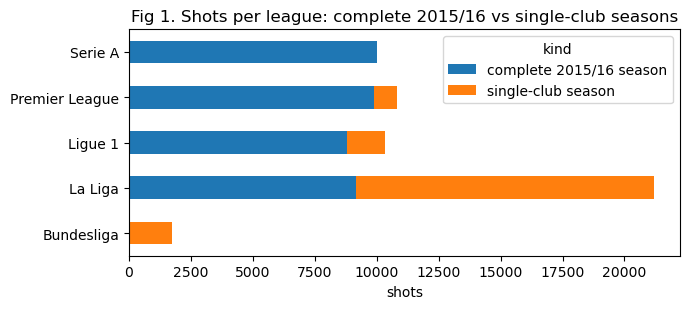

In [8]:
display(summary_out.sort_values(["subset_1516", "shots"], ascending=False).reset_index(drop=True))

kind = np.where(summary_out["subset_1516"], "complete 2015/16 season", "single-club season")
agg = summary_out.assign(kind=kind).groupby(["league", "kind"])["shots"].sum().unstack(fill_value=0)
ax = agg.plot.barh(stacked=True, figsize=(7, 3.2), color=["tab:blue", "tab:orange"])
ax.set_xlabel("shots"); ax.set_ylabel(""); ax.set_title("Fig 1. Shots per league: complete 2015/16 vs single-club seasons")
plt.tight_layout(); plt.savefig(FIGURES / "fig01_data_composition.png", dpi=150); plt.show()

## 1.8 Save the raw CSVs

In [9]:
summary_out.to_csv(RAW / "summary.csv", index=False)
matches_df.to_csv(RAW / "matches.csv", index=False)
shots_out.to_csv(RAW / "shots.csv", index=False)
freeze_frames_out.to_csv(RAW / "freeze_frames.csv", index=False)
for name in ["summary", "matches", "shots", "freeze_frames"]:
    print(f"saved data/raw/{name}.csv")

saved data/raw/summary.csv
saved data/raw/matches.csv
saved data/raw/shots.csv
saved data/raw/freeze_frames.csv


---
# Stage 2: model-ready tables

Writes two tables, linked by `shot_id`:
* **`shot_table.csv`**: one row per shot. Shot context features, the label `is_goal`, flags for the subsets, and a train/val/test split.
* **`player_table.csv`**: one row per player per shot, **including the shooter** as its own row (`is_shooter = 1`),
  so both models can treat the shooter as one of the players.

Player features come in two groups, so the analysis can switch the second group on and off:
* **basic**: where the player is relative to the shooter and the goal, team, keeper, position group;
* **engineered**: hand-made shooting geometry (distance to the shot line, inside the shooting cone, distance to the
  edge of the cone, fraction of the goal the player blocks).

## 2.1 Load and filter
Penalties are dropped (almost none have a freeze frame, and the other players barely matter for a penalty).
Free kicks are kept. Shots without a freeze frame are dropped.

In [10]:
SEED = 42
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}

shots = pd.read_csv(RAW / "shots.csv", dtype={"focus_team": "string"})
ff = pd.read_csv(RAW / "freeze_frames.csv")
n0 = len(shots)
shots = shots[shots["shot_type"] != "Penalty"]
print(f"dropped {n0 - len(shots):,} penalties")
n1 = len(shots)
shots = shots[shots["has_freeze_frame"]].reset_index(drop=True)
print(f"dropped {n1 - len(shots):,} shots without a freeze frame -> kept {len(shots):,} shots")
ff = ff[ff["shot_id"].isin(shots["shot_id"])].copy()

dropped 597 penalties
dropped 0 shots without a freeze frame -> kept 53,556 shots


## 2.2 Geometry helpers
Goal centre is (120, 40), posts at y = 36 and y = 44. The **shooting cone** is the triangle shooter → left post → right post.

In [11]:
def goal_angle(sx, sy):
    # Angle (radians) between the two posts as seen from (sx, sy).
    return np.abs(np.arctan2(POST_HIGH - sy, GOAL_X - sx) - np.arctan2(POST_LOW - sy, GOAL_X - sx))

def in_shooting_cone(px, py, sx, sy):
    def side(x1, y1, x2, y2, x3, y3):
        return (x1 - x3) * (y2 - y3) - (x2 - x3) * (y1 - y3)
    d1 = side(px, py, sx, sy, GOAL_X, POST_LOW)
    d2 = side(px, py, GOAL_X, POST_LOW, GOAL_X, POST_HIGH)
    d3 = side(px, py, GOAL_X, POST_HIGH, sx, sy)
    has_neg = (d1 < 0) | (d2 < 0) | (d3 < 0)
    has_pos = (d1 > 0) | (d2 > 0) | (d3 > 0)
    return ~(has_neg & has_pos)

def dist_to_segment(px, py, ax, ay, bx, by):
    # Shortest distance from point P to the segment A-B.
    vx, vy = bx - ax, by - ay
    t = np.clip(((px - ax) * vx + (py - ay) * vy) / np.maximum(vx * vx + vy * vy, 1e-9), 0, 1)
    return np.hypot(px - (ax + t * vx), py - (ay + t * vy))

def goal_blocked_fraction(px, py, sx, sy):
    # Fraction of the goal (as an angle seen from the shooter) covered by a player of radius BODY_RADIUS.
    # Only players between the shooter and the goal line can block.
    a_low = np.arctan2(POST_LOW - sy, GOAL_X - sx)
    a_high = np.arctan2(POST_HIGH - sy, GOAL_X - sx)
    d = np.hypot(px - sx, py - sy)
    a_p = np.arctan2(py - sy, px - sx)
    half = np.arctan(BODY_RADIUS / np.maximum(d, BODY_RADIUS))
    overlap = np.clip(np.minimum(a_p + half, a_high) - np.maximum(a_p - half, a_low), 0, None)
    between = (px > sx) & (px <= GOAL_X)
    return np.where(between, overlap / np.maximum(a_high - a_low, 1e-6), 0.0).clip(0, 1)

POSITION_GROUP = {
    "Goalkeeper": "GK",
    "Center Back": "DEF", "Left Center Back": "DEF", "Right Center Back": "DEF",
    "Left Back": "DEF", "Right Back": "DEF", "Left Wing Back": "DEF", "Right Wing Back": "DEF",
    "Center Defensive Midfield": "MID", "Left Defensive Midfield": "MID", "Right Defensive Midfield": "MID",
    "Center Midfield": "MID", "Left Center Midfield": "MID", "Right Center Midfield": "MID",
    "Left Midfield": "MID", "Right Midfield": "MID",
    "Center Attacking Midfield": "MID", "Left Attacking Midfield": "MID", "Right Attacking Midfield": "MID",
    "Center Forward": "FWD", "Left Center Forward": "FWD", "Right Center Forward": "FWD",
    "Secondary Striker": "FWD", "Left Wing": "FWD", "Right Wing": "FWD",
}

## 2.3 `shot_table`
Coordinates are scaled by fixed pitch constants (x / 120, y / 80, distances / 120), so everything is roughly 0–1
and no information leaks between splits. Categorical descriptors are one-hot encoded.

**Split by match, not by shot:** shots from the same match are correlated, so whole matches go to train, validation or test.
The split is seeded, so every model sees exactly the same split.

In [12]:
sx = shots["location_x"].clip(0, PITCH_L)
sy = shots["location_y"].clip(0, PITCH_W)
dist_goal = np.hypot(GOAL_X - sx, GOAL_Y - sy)

shot_table = pd.DataFrame({
    # identifiers and flags (not features)
    "shot_id": shots["shot_id"], "match_id": shots["match_id"], "league": shots["league"], "season": shots["season"],
    "team": shots["team"], "subset_1516": shots["subset_1516"].astype(int),
    "season_complete": shots["season_complete"].astype(int), "is_focus_team": shots["is_focus_team"].astype(int),
    # label and benchmark (not features)
    "is_goal": shots["is_goal"].astype(int), "statsbomb_xg": shots["statsbomb_xg"],
    # raw geometry in yards (for plots and the graph builder)
    "location_x": sx, "location_y": sy,
    # shot context features
    "x_norm": sx / PITCH_L, "y_norm": sy / PITCH_W,
    "lateral_offset": (sy - GOAL_Y).abs() / GOAL_Y,
    "dist_to_goal_norm": dist_goal / PITCH_L,
    "goal_angle": goal_angle(sx, sy),
    "under_pressure": shots["under_pressure"].astype(int),
    "first_time": shots["first_time"].astype(int),
})
onehot_cols = []
for col, prefix in [("body_part", "body"), ("shot_type", "type"), ("technique", "tech"), ("play_pattern", "pattern")]:
    dummies = pd.get_dummies(shots[col], prefix=prefix, dtype=int)
    dummies.columns = [c.replace(" ", "_").replace("-", "_") for c in dummies.columns]
    onehot_cols += list(dummies.columns)
    shot_table = pd.concat([shot_table, dummies], axis=1)

# match-level split
rng = np.random.default_rng(SEED)
unique_matches = np.sort(shot_table["match_id"].unique())
rng.shuffle(unique_matches)
n_train = int(SPLIT_FRACTIONS["train"] * len(unique_matches))
n_val = int(SPLIT_FRACTIONS["val"] * len(unique_matches))
split_of = {m: "train" if i < n_train else ("val" if i < n_train + n_val else "test")
            for i, m in enumerate(unique_matches)}
shot_table.insert(4, "split", shot_table["match_id"].map(split_of))

print(shot_table.groupby(["split", "subset_1516"]).agg(matches=("match_id", "nunique"), shots=("shot_id", "size"),
                                                        goal_rate=("is_goal", "mean")).round(3))

                   matches  shots  goal_rate
split subset_1516                           
test  0                 94   2355      0.121
      1                232   5728      0.091
train 0                456  11225      0.121
      1               1062  26239      0.095
val   0                102   2488      0.128
      1                223   5521      0.101


## 2.4 `player_table`
One row per player per shot. The shooter is added as an extra row at the shot location.

| group | features |
|---|---|
| basic | `x_norm`, `y_norm`, `dx_to_shooter`, `dy_to_shooter`, `dist_to_shooter`, `dist_to_goal`, `teammate`, `is_keeper`, `is_shooter`, `pos_GK/DEF/MID/FWD` |
| engineered | `dist_to_shot_line` (to the line shooter → goal centre), `in_cone`, `cone_clearance` (distance to the nearest edge of the cone, + inside, − outside), `goal_blocked` (fraction of the goal angle the player covers) |

`x`, `y` are kept in raw yards because the graph builder needs them; they are not model inputs.
`teammate` means "on the shooter's team", so the shooter row has `teammate = 1`.

In [13]:
shooter_pos = pd.DataFrame({"shot_id": shots["shot_id"], "sx": sx, "sy": sy})
players = ff.merge(shooter_pos, on="shot_id", how="inner")
unmapped = set(players["position"].dropna().unique()) - set(POSITION_GROUP)
assert not unmapped, f"Positions missing from POSITION_GROUP: {unmapped}"
players["is_shooter"] = 0

# the shooter as an extra node
shooter_rows = shooter_pos.rename(columns={"sx": "x", "sy": "y"}).assign(
    teammate=True, is_keeper=False, position=None, is_shooter=1)
shooter_rows[["sx", "sy"]] = shooter_pos[["sx", "sy"]].values
players = pd.concat([players, shooter_rows], ignore_index=True)

px, py = players["x"].clip(0, PITCH_L), players["y"].clip(0, PITCH_W)
psx, psy = players["sx"], players["sy"]
is_sh = players["is_shooter"].values == 1

line_dx, line_dy = GOAL_X - psx, GOAL_Y - psy
line_len = np.maximum(np.hypot(line_dx, line_dy), 1e-6)
dist_line = np.abs(line_dx * (py - psy) - line_dy * (px - psx)) / line_len
cone = in_shooting_cone(px, py, psx, psy) & ~is_sh
clear = np.minimum(dist_to_segment(px, py, psx, psy, GOAL_X, POST_LOW),
                   dist_to_segment(px, py, psx, psy, GOAL_X, POST_HIGH))
group = players["position"].map(POSITION_GROUP)

player_table = pd.DataFrame({
    "shot_id": players["shot_id"],
    "x": px, "y": py,                                   # raw yards, not model inputs
    # basic
    "x_norm": px / PITCH_L, "y_norm": py / PITCH_W,
    "dx_to_shooter": (px - psx) / PITCH_L, "dy_to_shooter": (py - psy) / PITCH_L,
    "dist_to_shooter": np.hypot(px - psx, py - psy) / PITCH_L,
    "dist_to_goal": np.hypot(GOAL_X - px, GOAL_Y - py) / PITCH_L,
    "teammate": players["teammate"].astype(int), "is_keeper": players["is_keeper"].astype(int),
    "is_shooter": players["is_shooter"].astype(int),
    "pos_GK": (group == "GK").astype(int), "pos_DEF": (group == "DEF").astype(int),
    "pos_MID": (group == "MID").astype(int), "pos_FWD": (group == "FWD").astype(int),
    # engineered
    "dist_to_shot_line": np.where(is_sh, 0, dist_line) / PITCH_L,
    "in_cone": cone.astype(int),
    "cone_clearance": np.where(is_sh, 0, np.where(cone, clear, -clear)) / PITCH_L,
    "goal_blocked": np.where(is_sh, 0, goal_blocked_fraction(px, py, psx, psy)),
})
# shooter first, then nearest to the shooter first
player_table = (player_table.assign(_o=1 - player_table["is_shooter"])
                .sort_values(["shot_id", "_o", "dist_to_shooter"], kind="stable").drop(columns="_o")
                .reset_index(drop=True))
player_table.insert(1, "player_idx", player_table.groupby("shot_id").cumcount())
print(f"player_table: {player_table.shape}")
player_table.head()

player_table: (738529, 21)


,shot_id,player_idx,x,y,x_norm,y_norm,dx_to_shooter,dy_to_shooter,dist_to_shooter,dist_to_goal,...,is_keeper,is_shooter,pos_GK,pos_DEF,pos_MID,pos_FWD,dist_to_shot_line,in_cone,cone_clearance,goal_blocked
0,00007fd2-738e-4b27-bb68-7bdeffc77ee7,0,101.2,24.0,0.843333,0.30000,0.000000,0.000000,0.000000,0.205724,...,0,1,0,0,0,0,0.000000,0,0.000000,0.000000
1,00007fd2-738e-4b27-bb68-7bdeffc77ee7,1,102.1,23.8,0.850833,0.29750,0.007500,-0.001667,0.007683,0.201186,...,0,0,0,1,0,0,0.006130,0,-0.005440,0.000000
2,00007fd2-738e-4b27-bb68-7bdeffc77ee7,2,102.1,25.4,0.850833,0.31750,0.007500,0.011667,0.013869,0.192493,...,0,0,0,1,0,0,0.004024,0,-0.002526,0.437934
3,00007fd2-738e-4b27-bb68-7bdeffc77ee7,3,94.4,30.8,0.786667,0.38500,-0.056667,0.056667,0.080139,0.226691,...,0,0,0,0,1,0,0.079881,0,-0.080100,0.000000
4,00007fd2-738e-4b27-bb68-7bdeffc77ee7,4,102.2,38.7,0.851667,0.48375,0.008333,0.122500,0.122783,0.148728,...,0,0,0,0,1,0,0.087888,0,-0.077830,0.000000


## 2.5 Checks on the processed tables

In [14]:
CHECKS.clear()
SHOT_FEATURES = ["x_norm", "y_norm", "lateral_offset", "dist_to_goal_norm", "goal_angle",
                 "under_pressure", "first_time"] + onehot_cols
PLAYER_BASIC = ["x_norm", "y_norm", "dx_to_shooter", "dy_to_shooter", "dist_to_shooter", "dist_to_goal",
                "teammate", "is_keeper", "is_shooter", "pos_GK", "pos_DEF", "pos_MID", "pos_FWD"]
PLAYER_ENGINEERED = ["dist_to_shot_line", "in_cone", "cone_clearance", "goal_blocked"]

check("shot_id unique in shot_table", shot_table["shot_id"].is_unique)
check("No penalties remain", (shots["shot_type"] != "Penalty").all())
check("No missing shot features / label", shot_table[SHOT_FEATURES + ["is_goal", "split"]].notna().all().all())
check("No missing player features", player_table[PLAYER_BASIC + PLAYER_ENGINEERED].notna().all().all())
check("Same shots in both tables", set(shot_table["shot_id"]) == set(player_table["shot_id"]))
check("Exactly one shooter per shot", (player_table.groupby("shot_id")["is_shooter"].sum() == 1).all())
check("Shooter is the first row of each shot",
      (player_table.loc[player_table["player_idx"] == 0, "is_shooter"] == 1).all())
check("Scaled coordinates within [0, 1]", player_table[["x_norm", "y_norm"]].stack().between(0, 1).all())
check("goal_blocked within [0, 1]", player_table["goal_blocked"].between(0, 1).all())
check("No match in more than one split", (shot_table.groupby("match_id")["split"].nunique() == 1).all())
check("All three splits contain 2015/16 matches",
      shot_table.loc[shot_table["subset_1516"] == 1, "split"].nunique() == 3)
print(f"\n{sum(ok for _, ok, _ in CHECKS)}/{len(CHECKS)} checks passed")

PASS  shot_id unique in shot_table  
PASS  No penalties remain  
PASS  No missing shot features / label  
PASS  No missing player features  
PASS  Same shots in both tables  
PASS  Exactly one shooter per shot  
PASS  Shooter is the first row of each shot  
PASS  Scaled coordinates within [0, 1]  
PASS  goal_blocked within [0, 1]  
PASS  No match in more than one split  
PASS  All three splits contain 2015/16 matches  

11/11 checks passed


## 2.6 Example freeze frame
One shot drawn with the engineered features: the shooting cone, and each player's share of the goal they block.
This is a sanity check that the geometry is right.

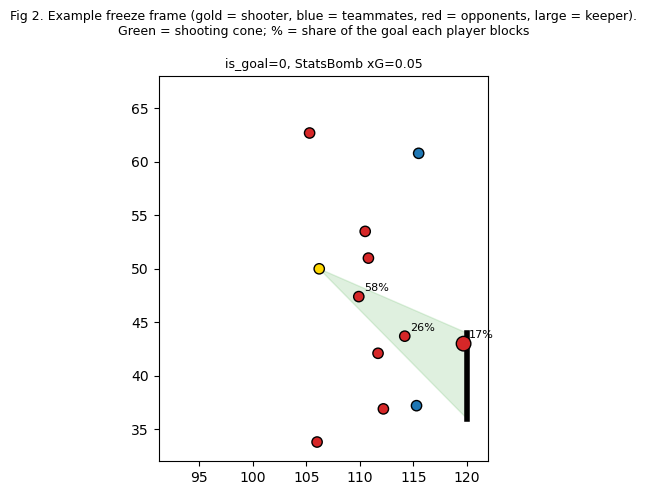

In [15]:
def draw_frame(shot_id, ax):
    s = shot_table.set_index("shot_id").loc[shot_id]
    p = player_table[player_table["shot_id"] == shot_id]
    ax.add_patch(plt.Polygon([[s.location_x, s.location_y], [GOAL_X, POST_LOW], [GOAL_X, POST_HIGH]],
                             color="tab:green", alpha=0.15))
    ax.plot([GOAL_X, GOAL_X], [POST_LOW, POST_HIGH], color="k", lw=4)
    col = np.where(p["is_shooter"] == 1, "gold", np.where(p["teammate"] == 1, "tab:blue", "tab:red"))
    ax.scatter(p["x"], p["y"], c=col, s=np.where(p["is_keeper"] == 1, 110, 55), edgecolor="k", zorder=3)
    for _, r in p[p["goal_blocked"] > 0.01].iterrows():
        ax.annotate(f"{r.goal_blocked:.0%}", (r.x, r.y), xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.set_xlim(s.location_x - 15, 122); ax.set_ylim(s.location_y - 18, s.location_y + 18); ax.set_aspect("equal")
    ax.set_title(f"is_goal={int(s.is_goal)}, StatsBomb xG={s.statsbomb_xg:.2f}", fontsize=9)

n_blockers = player_table.groupby("shot_id")["in_cone"].sum()
example = shot_table[(shot_table["shot_id"].isin(n_blockers[n_blockers.between(2, 3)].index))
                     & (shot_table["dist_to_goal_norm"] * PITCH_L).between(12, 20)]["shot_id"].iloc[0]
fig, ax = plt.subplots(figsize=(6, 5))
draw_frame(example, ax)
fig.suptitle("Fig 2. Example freeze frame (gold = shooter, blue = teammates, red = opponents, large = keeper).\n"
             "Green = shooting cone; % = share of the goal each player blocks", fontsize=9)
plt.tight_layout(); plt.savefig(FIGURES / "fig02_example_freeze_frame.png", dpi=150); plt.show()

## 2.7 Save to `data/processed`

In [16]:
shot_table.to_csv(PROCESSED / "shot_table.csv", index=False, float_format="%.6f")
player_table.to_csv(PROCESSED / "player_table.csv", index=False, float_format="%.6f")
feature_columns = {"shot_features": SHOT_FEATURES, "player_basic": PLAYER_BASIC,
                   "player_engineered": PLAYER_ENGINEERED, "player_raw_xy": ["x", "y"],
                   "label": "is_goal", "benchmark_only": "statsbomb_xg"}
(PROCESSED / "feature_columns.json").write_text(json.dumps(feature_columns, indent=2))

for name, df in [("shot_table", shot_table), ("player_table", player_table)]:
    print(f"saved data/processed/{name}.csv  rows={df.shape[0]:,}  cols={df.shape[1]}")
print("saved data/processed/feature_columns.json")

saved data/processed/shot_table.csv  rows=53,556  cols=43
saved data/processed/player_table.csv  rows=738,529  cols=21
saved data/processed/feature_columns.json
